In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("ecommerce_dirty_sample.csv")

In [2]:
df.head()

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,total_amount,payment_method,order_status,city
0,ORD1001,2026-01-03,CUST001,Laptop,Electronics,1,899.99,899.99,Credit Card,Shipped,Chennai
1,ORD1002,2026-01-04,CUST002,wireless mouse,Electronics,2,19.99,39.98,UPI,Delivered,Bengaluru
2,ORD1003,2026-01-05,CUST003,Office Chair,Furniture,1,149.50,149.50,Cash on Delivery,Delivered,Mumbai
3,ORD1004,2026-01-06,CUST004,Smartphone,Electronics,1,699.00,699.00,NaN,Processing,Hyderabad
4,ORD1005,2026-01-07,CUST005,Coffee Maker,Home Appliances,2,45.00,90.00,UPI,Delivered,Pune


In [3]:
df.shape

(104, 11)

In [4]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'product_name', 'category',
       'quantity', 'unit_price', 'total_amount', 'payment_method',
       'order_status', 'city'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        104 non-null    str    
 1   order_date      103 non-null    str    
 2   customer_id     101 non-null    str    
 3   product_name    103 non-null    str    
 4   category        103 non-null    str    
 5   quantity        104 non-null    str    
 6   unit_price      102 non-null    float64
 7   total_amount    102 non-null    float64
 8   payment_method  103 non-null    str    
 9   order_status    103 non-null    str    
 10  city            103 non-null    str    
dtypes: float64(2), str(9)
memory usage: 9.1 KB


In [6]:
df.isnull().sum()

order_id          0
order_date        1
customer_id       3
product_name      1
category          1
quantity          0
unit_price        2
total_amount      2
payment_method    1
order_status      1
city              1
dtype: int64

In [7]:
df.describe()

,unit_price,total_amount
count,102.000000,1.020000e+02
mean,9976.214706,9.824241e+04
std,98997.900387,9.901273e+05
min,-45.000000,0.000000e+00
25%,22.500000,4.800000e+01
50%,59.990000,8.997000e+01
75%,149.500000,1.495000e+02
max,999999.990000,1.000000e+07


In [8]:
df.duplicated().sum()

np.int64(3)

In [9]:
df[df.duplicated()]

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,total_amount,payment_method,order_status,city
100,ORD1002,2026-01-04,CUST002,wireless mouse,Electronics,2,19.99,39.98,UPI,Delivered,Bengaluru
101,ORD1009,not-a-date,CUST009,Desk Lamp,Home Decor,2,24.50,49.00,Debit Card,Delivered,Jaipur
102,ORD1016,2026-01-18,CUST016,laptop,Electronics,1,899.99,899.99,credit card,Shipped,Chennai


In [10]:
df = df.drop_duplicates()

In [11]:
df[df.duplicated()]

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,total_amount,payment_method,order_status,city


In [12]:
df.info()


<class 'pandas.DataFrame'>
Index: 101 entries, 0 to 103
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        101 non-null    str    
 1   order_date      100 non-null    str    
 2   customer_id     98 non-null     str    
 3   product_name    100 non-null    str    
 4   category        100 non-null    str    
 5   quantity        101 non-null    str    
 6   unit_price      99 non-null     float64
 7   total_amount    99 non-null     float64
 8   payment_method  100 non-null    str    
 9   order_status    100 non-null    str    
 10  city            100 non-null    str    
dtypes: float64(2), str(9)
memory usage: 9.5 KB


In [13]:
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")
df["total_amount"] = pd.to_numeric(df["total_amount"], errors="coerce")

In [14]:
df.info()

<class 'pandas.DataFrame'>
Index: 101 entries, 0 to 103
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        101 non-null    str           
 1   order_date      97 non-null     datetime64[us]
 2   customer_id     98 non-null     str           
 3   product_name    100 non-null    str           
 4   category        100 non-null    str           
 5   quantity        99 non-null     float64       
 6   unit_price      99 non-null     float64       
 7   total_amount    99 non-null     float64       
 8   payment_method  100 non-null    str           
 9   order_status    100 non-null    str           
 10  city            100 non-null    str           
dtypes: datetime64[us](1), float64(3), str(7)
memory usage: 9.5 KB


In [15]:
df.isnull().sum()

order_id          0
order_date        4
customer_id       3
product_name      1
category          1
quantity          2
unit_price        2
total_amount      2
payment_method    1
order_status      1
city              1
dtype: int64

In [16]:
df["product_name"] = df["product_name"].str.strip().str.title()
df["category"] = df["category"].str.strip().str.title()
df["payment_method"] = df["payment_method"].str.strip().str.title()
df["order_status"] = df["order_status"].str.strip().str.title()
df["city"] = df["city"].str.strip().str.title()

In [17]:
df.info()

<class 'pandas.DataFrame'>
Index: 101 entries, 0 to 103
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        101 non-null    str           
 1   order_date      97 non-null     datetime64[us]
 2   customer_id     98 non-null     str           
 3   product_name    100 non-null    str           
 4   category        100 non-null    str           
 5   quantity        99 non-null     float64       
 6   unit_price      99 non-null     float64       
 7   total_amount    99 non-null     float64       
 8   payment_method  100 non-null    str           
 9   order_status    100 non-null    str           
 10  city            100 non-null    str           
dtypes: datetime64[us](1), float64(3), str(7)
memory usage: 9.5 KB


In [18]:
df.isnull().sum()

order_id          0
order_date        4
customer_id       3
product_name      1
category          1
quantity          2
unit_price        2
total_amount      2
payment_method    1
order_status      1
city              1
dtype: int64

In [19]:
df[df["quantity"] < 0]

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,total_amount,payment_method,order_status,city
39,ORD1040,2026-02-11,CUST040,Water Bottle,Home & Kitchen,-2.0,12.0,48.0,Upi,Delivered,Ahmedabad


In [20]:
df[df["unit_price"] < 0]

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,total_amount,payment_method,order_status,city
64,ORD1065,2026-03-08,CUST065,Coffee Maker,Home Appliances,2.0,-45.0,90.0,Upi,Delivered,Pune


In [21]:
df[df["total_amount"] <= 0]

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,total_amount,payment_method,order_status,city
42,ORD1043,2026-02-14,CUST043,Gaming Keyboard,Electronics,1.0,89.99,0.0,Upi,Processing,Bengaluru


In [22]:
def fix_invalid(value):
    if pd.isna(value):
        return np.nan
    if value < 0:
        return np.nan
    return value

df["quantity"] = df["quantity"].apply(fix_invalid)
df["unit_price"] = df["unit_price"].apply(fix_invalid)
df["total_amount"] = df["total_amount"].apply(lambda x: np.nan if pd.notna(x) and x <= 0 else x)

df = df.dropna()

In [24]:
df[(df["quantity"] < 0) | (df["unit_price"] < 0) | (df["total_amount"] <= 0)]

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,total_amount,payment_method,order_status,city


In [32]:
df["calculated_total"] = df["quantity"] * df["unit_price"]
df["total_difference"] = df["total_amount"] - df["calculated_total"]

In [38]:
df["order_date"].isna().sum()

np.int64(0)

In [39]:
df["quantity"].isna().sum()

np.int64(0)

In [40]:
df["unit_price"].isna().sum()

np.int64(0)

In [41]:
df["total_amount"].isna().sum()

np.int64(0)

<Axes: >

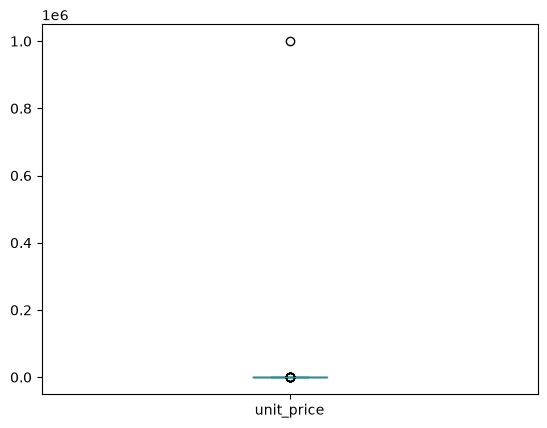

In [42]:
df["unit_price"].plot(kind="box")

<Axes: >

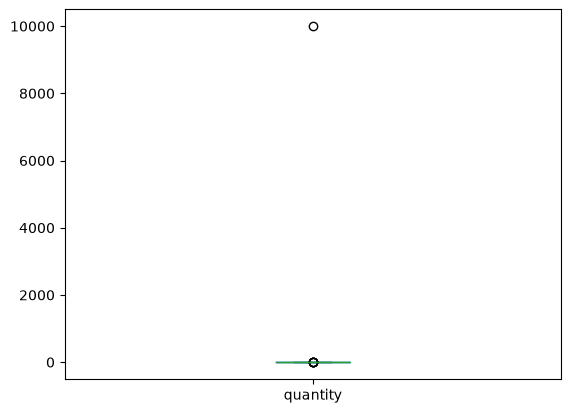

In [43]:
df["quantity"].plot(kind="box")

In [44]:
Q1 = df["unit_price"].quantile(0.25)
Q3 = df["unit_price"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [45]:
df[(df["unit_price"] < lower_bound) | (df["unit_price"] > upper_bound)]

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,total_amount,payment_method,order_status,city,calculated_total,total_difference
0,ORD1001,2026-01-03,CUST001,Laptop,Electronics,1.0,899.99,899.99,Credit Card,Shipped,Chennai,899.99,0.00
15,ORD1016,2026-01-18,CUST016,Laptop,Electronics,1.0,899.99,899.99,Credit Card,Shipped,Chennai,899.99,0.00
33,ORD1034,2026-02-05,CUST034,Smartphone,Electronics,1.0,699.00,699.00,Credit Card,Processing,Hyderabad,699.00,0.00
35,ORD1036,2026-02-07,CUST036,Running Shoes,Fashion,1.0,999999.99,79.99,Debit Card,Shipped,Delhi,999999.99,-999920.00
48,ORD1049,2026-02-20,CUST049,Smartphone,Electronics,1.0,699.00,699.00,Credit Card,Processing,Hyderabad,699.00,0.00
60,ORD1061,2026-03-04,CUST061,Laptop,Electronics,10000.0,899.99,899.99,Credit Card,Shipped,Chennai,8999900.00,-8999000.01
63,ORD1064,2026-03-07,CUST064,Smartphone,Electronics,1.0,699.00,699.00,Credit Card,Processing,Hyderabad,699.00,0.00
75,ORD1076,2026-03-19,CUST076,Wireless Mouse,Electronics,1.0,899.99,899.99,Credit Card,Shipped,Chennai,899.99,0.00
78,ORD1079,2026-03-22,CUST079,Smartphone,Electronics,1.0,699.00,699.00,Credit Card,Processing,Hyderabad,699.00,0.00
93,ORD1094,2026-04-06,CUST094,Smartphone,Electronics,1.0,699.00,699.00,Credit Card,Processing,Hyderabad,699.00,0.00


In [46]:
df.at[35,'unit_price']=999

In [47]:
df[(df["unit_price"] < lower_bound) | (df["unit_price"] > upper_bound)]

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,total_amount,payment_method,order_status,city,calculated_total,total_difference
0,ORD1001,2026-01-03,CUST001,Laptop,Electronics,1.0,899.99,899.99,Credit Card,Shipped,Chennai,899.99,0.00
15,ORD1016,2026-01-18,CUST016,Laptop,Electronics,1.0,899.99,899.99,Credit Card,Shipped,Chennai,899.99,0.00
33,ORD1034,2026-02-05,CUST034,Smartphone,Electronics,1.0,699.00,699.00,Credit Card,Processing,Hyderabad,699.00,0.00
35,ORD1036,2026-02-07,CUST036,Running Shoes,Fashion,1.0,999.00,79.99,Debit Card,Shipped,Delhi,999999.99,-999920.00
48,ORD1049,2026-02-20,CUST049,Smartphone,Electronics,1.0,699.00,699.00,Credit Card,Processing,Hyderabad,699.00,0.00
60,ORD1061,2026-03-04,CUST061,Laptop,Electronics,10000.0,899.99,899.99,Credit Card,Shipped,Chennai,8999900.00,-8999000.01
63,ORD1064,2026-03-07,CUST064,Smartphone,Electronics,1.0,699.00,699.00,Credit Card,Processing,Hyderabad,699.00,0.00
75,ORD1076,2026-03-19,CUST076,Wireless Mouse,Electronics,1.0,899.99,899.99,Credit Card,Shipped,Chennai,899.99,0.00
78,ORD1079,2026-03-22,CUST079,Smartphone,Electronics,1.0,699.00,699.00,Credit Card,Processing,Hyderabad,699.00,0.00
93,ORD1094,2026-04-06,CUST094,Smartphone,Electronics,1.0,699.00,699.00,Credit Card,Processing,Hyderabad,699.00,0.00


In [48]:
Q1 = df["quantity"].quantile(0.25)
Q3 = df["quantity"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [49]:
df[(df["quantity"] < lower_bound) | (df["quantity"] > upper_bound)]

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,total_amount,payment_method,order_status,city,calculated_total,total_difference
26,ORD1027,2026-01-29,CUST027,Notebook Set,Stationery,5.0,4.99,24.95,Cash On Delivery,Delivered,Lucknow,24.95,-3.552714e-15
41,ORD1042,2026-02-13,CUST042,Notebook Set,Stationery,5.0,4.99,24.95,Cash On Delivery,Delivered,Lucknow,24.95,-3.552714e-15
56,ORD1057,2026-02-28,CUST057,Notebook Set,Stationery,5.0,4.99,24.95,Cash On Delivery,Delivered,Lucknow,24.95,-3.552714e-15
60,ORD1061,2026-03-04,CUST061,Laptop,Electronics,10000.0,899.99,899.99,Credit Card,Shipped,Chennai,8999900.00,-8.999000e+06
71,ORD1072,2026-03-15,CUST072,Notebook Set,Stationery,5.0,4.99,24.95,Cash On Delivery,Delivered,Lucknow,24.95,-3.552714e-15
86,ORD1087,2026-03-30,CUST087,Notebook Set,Stationery,5.0,4.99,24.95,Cash On Delivery,Delivered,Lucknow,24.95,-3.552714e-15


In [50]:
df.at[60,'quantity']=1

In [51]:
df[(df["quantity"] < lower_bound) | (df["quantity"] > upper_bound)]

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,total_amount,payment_method,order_status,city,calculated_total,total_difference
26,ORD1027,2026-01-29,CUST027,Notebook Set,Stationery,5.0,4.99,24.95,Cash On Delivery,Delivered,Lucknow,24.95,-3.552714e-15
41,ORD1042,2026-02-13,CUST042,Notebook Set,Stationery,5.0,4.99,24.95,Cash On Delivery,Delivered,Lucknow,24.95,-3.552714e-15
56,ORD1057,2026-02-28,CUST057,Notebook Set,Stationery,5.0,4.99,24.95,Cash On Delivery,Delivered,Lucknow,24.95,-3.552714e-15
71,ORD1072,2026-03-15,CUST072,Notebook Set,Stationery,5.0,4.99,24.95,Cash On Delivery,Delivered,Lucknow,24.95,-3.552714e-15
86,ORD1087,2026-03-30,CUST087,Notebook Set,Stationery,5.0,4.99,24.95,Cash On Delivery,Delivered,Lucknow,24.95,-3.552714e-15


In [55]:
df.isnull().sum()

order_id            0
order_date          0
customer_id         0
product_name        0
category            0
quantity            0
unit_price          0
total_amount        0
payment_method      0
order_status        0
city                0
calculated_total    0
total_difference    0
dtype: int64

In [56]:
df.duplicated().sum()

np.int64(0)

In [57]:
df.info()

<class 'pandas.DataFrame'>
Index: 80 entries, 0 to 103
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          80 non-null     str           
 1   order_date        80 non-null     datetime64[us]
 2   customer_id       80 non-null     str           
 3   product_name      80 non-null     str           
 4   category          80 non-null     str           
 5   quantity          80 non-null     float64       
 6   unit_price        80 non-null     float64       
 7   total_amount      80 non-null     float64       
 8   payment_method    80 non-null     str           
 9   order_status      80 non-null     str           
 10  city              80 non-null     str           
 11  calculated_total  80 non-null     float64       
 12  total_difference  80 non-null     float64       
dtypes: datetime64[us](1), float64(5), str(7)
memory usage: 10.8 KB


In [58]:
df.describe()

,order_date,quantity,unit_price,total_amount,calculated_total,total_difference
count,80,80.000000,80.000000,8.000000e+01,8.000000e+01,8.000000e+01
mean,2026-02-25 02:06:00,1.968750,160.607125,1.251777e+05,1.251555e+05,2.218769e+01
min,2026-01-03 00:00:00,1.000000,4.990000,2.495000e+01,2.495000e+01,-8.999000e+06
25%,2026-02-02 12:00:00,1.000000,22.500000,4.800000e+01,4.800000e+01,0.000000e+00
50%,2026-02-26 12:00:00,2.000000,45.000000,8.997000e+01,8.997000e+01,0.000000e+00
75%,2026-03-20 06:00:00,2.000000,129.990000,1.348675e+02,1.348675e+02,0.000000e+00
max,2026-04-12 00:00:00,5.000000,999.000000,1.000000e+07,8.999900e+06,9.999951e+06
std,NaN,1.212654,264.959799,1.118014e+06,1.010985e+06,1.517747e+06


In [59]:
df.head()

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,total_amount,payment_method,order_status,city,calculated_total,total_difference
0,ORD1001,2026-01-03,CUST001,Laptop,Electronics,1.0,899.99,899.99,Credit Card,Shipped,Chennai,899.99,0.0
1,ORD1002,2026-01-04,CUST002,Wireless Mouse,Electronics,2.0,19.99,39.98,Upi,Delivered,Bengaluru,39.98,0.0
2,ORD1003,2026-01-05,CUST003,Office Chair,Furniture,1.0,149.50,149.50,Cash On Delivery,Delivered,Mumbai,149.50,0.0
4,ORD1005,2026-01-07,CUST005,Coffee Maker,Home Appliances,2.0,45.00,90.00,Upi,Delivered,Pune,90.00,0.0
7,ORD1008,2026-01-10,CUST008,Bluetooth Speaker,Electronics,1.0,59.99,59.99,Paypal,Cancelled,Chennai,59.99,0.0


In [60]:
df.to_csv("ecommerce_cleaned.csv", index=False)